# 02 · Load and explore: încărcăm și explorăm un dataset audio

**Sursa:** [Load and explore an audio dataset](https://huggingface.co/learn/audio-course/en/chapter1/load_and_explore)
**Kernel:** `speech-vlm` (Mac). Ai nevoie de `pip install torchcodec`, pe care `datasets` 5 îl folosește ca să decodeze audio.

**Cum folosești ghidul:**
- 📖 **Teorie**: ce trebuie să reții, pe scurt.
- ▶️ **Cod din curs**: îl rulezi și te uiți la rezultat.
- 🔍 **Ce să observi**: unde să te uiți în grafic sau în output.
- 🧪 **Exercițiu**: cerința e în comentariile `# TODO`, iar soluția e chiar dedesubt. O rulezi, apoi o modifici ca să vezi ce se schimbă.
- 🎯 **Legătura cu proiectul**.

🎯 **De ce contează:** înainte să antrenezi un model, te uiți la date: ce câmpuri au, la ce sampling rate sunt, cât durează exemplele, ce etichete au. Exact asta vom face și cu dataset-ul proiectului, `speechbrain/LoquaciousSet`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
from IPython.display import Audio, display
from datasets import load_dataset

/Users/bceachi/miniforge3/envs/speech-vlm/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. 🤗 Datasets: un dataset într-o singură linie

📖 **Teorie**
- `load_dataset(id, name=..., split=...)` descarcă și pregătește un dataset de pe Hub. Parametrii:
  - `id`: identificatorul de pe Hub (ex. `"PolyAI/minds14"`);
  - `name`: **configurația**, adică subsetul (aici, limba);
  - `split`: `"train"`, `"test"` etc.
- **MINDS-14** conține înregistrări cu oameni care întreabă un sistem de e-banking ceva, în 14 limbi. Fiecare înregistrare are transcrierea și **intenția** (ex. `pay_bill`).
- La prima rulare se descarcă în `~/.cache/huggingface/`. După aceea se încarcă instant, din cache.

▶️ **Cod din curs**

In [2]:
minds = load_dataset("PolyAI/minds14", name="en-AU", split="train")
minds

Using the latest cached version of the dataset since PolyAI/minds14 couldn't be found on the Hugging Face Hub
Found the latest cached dataset configuration 'en-AU' at /Users/bceachi/.cache/huggingface/datasets/PolyAI___minds14/en-AU/0.0.0/40ce77cb32a384e4d50a568e1ec39ac804019d33 (last modified on Mon Nov 23 15:21:17 2026).


Dataset({
    features: ['path', 'audio', 'transcription', 'english_transcription', 'intent_class', 'lang_id'],
    num_rows: 654
})

🔍 **Ce să observi:** 654 de exemple și 6 coloane: `path`, `audio`, `transcription`, `english_transcription`, `intent_class`, `lang_id`.

## 2. Un exemplu în detaliu

📖 **Ce conține fiecare coloană:**
- `path`: calea fișierului audio (`.wav`).
- `audio`: audio-ul decodat, cu:
  - `array`: un vector NumPy 1-D, cu eșantioanele;
  - `sampling_rate`: rata de eșantionare.
- `transcription` / `english_transcription`: textul rostit, plus traducerea în engleză.
- `intent_class`: intenția, salvată ca număr.
- `lang_id`: limba, salvată ca număr.

> ⚠️ **Diferență față de curs:** în `datasets` 5, coloana `audio` e un obiect `AudioDecoder`, care decodează abia când îl folosești. Îl accesezi la fel ca în curs: `audio["array"]` și `audio["sampling_rate"]`.

▶️ **Cod din curs**, adaptat ca să afișeze clar:

In [3]:
example = minds[0]

print("path:         ", example["path"])
print("transcription:", example["transcription"])
print("intent_class: ", example["intent_class"], "| lang_id:", example["lang_id"])

audio = example["audio"]
print("tip audio:    ", type(audio).__name__)
print("sampling_rate:", audio["sampling_rate"])
print("array:        ", audio["array"][:5], "...", audio["array"].shape, audio["array"].dtype)

path:          en-AU~PAY_BILL/response_4.wav
transcription: I would like to pay my electricity bill using my card can you please assist
intent_class:  13 | lang_id: 2
tip audio:     AudioDecoder
sampling_rate: 8000
array:         [ 0.          0.00024414 -0.00024414  0.          0.        ] ... (62415,) float32


🔍 **Ce să observi**
- Sampling rate-ul e **8000 Hz**, nu 16.000. Pentru Whisper, care vrea 16 kHz, ar trebui **resampling**. Asta e tema modulului următor.
- `array` e `float32`, deja în [-1, 1].

## 3. Etichete: din număr în text

📖 `intent_class` e de tip `ClassLabel`. Stochează **numere**, iar lista de nume e în `features`. Cu `int2str` treci de la număr la nume.

▶️ **Cod din curs**

In [4]:
id2label = minds.features["intent_class"].int2str
id2label(example["intent_class"])

'pay_bill'

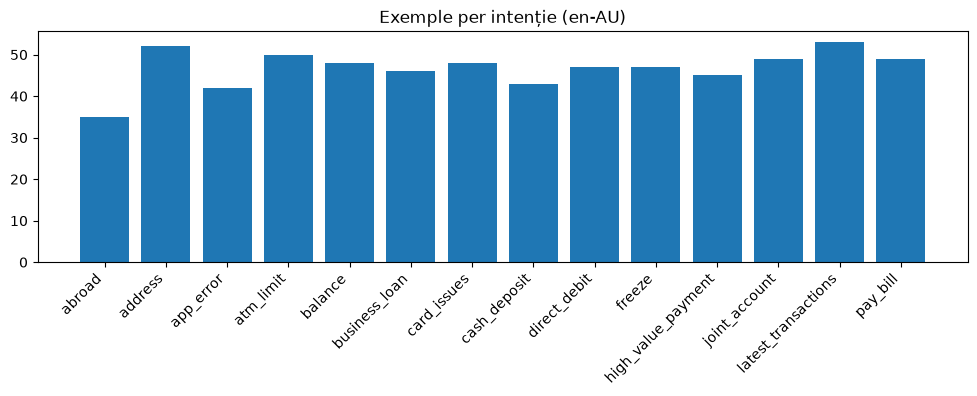

In [5]:
# 🧪 TODO: afișează toate cele 14 intenții și câte exemple are fiecare, ca grafic de bare.
names = minds.features["intent_class"].names
counts = np.bincount(minds["intent_class"], minlength=len(names))

plt.figure(figsize=(12, 3))
plt.bar(names, counts)
plt.xticks(rotation=45, ha="right"); plt.title("Exemple per intenție (en-AU)")
plt.show()
# Răspuns: între 35 și 53 de exemple pe clasă, deci relativ echilibrat.
# Contează la clasificare: pe un dataset dezechilibrat, modelul tinde să favorizeze clasa majoritară.

## 4. Scoatem coloanele de care nu avem nevoie

📖 În subsetul `en-AU`:
- `lang_id` are aceeași valoare peste tot;
- `english_transcription` repetă `transcription`.

Le scoatem cu `remove_columns`, care întoarce un **dataset nou**.

▶️ **Cod din curs**

In [6]:
columns_to_remove = ["lang_id", "english_transcription"]
minds = minds.remove_columns(columns_to_remove)
minds

Dataset({
    features: ['path', 'audio', 'transcription', 'intent_class'],
    num_rows: 654
})

In [7]:
# 🧪 TODO: verifică afirmația cursului. În en-AU, english_transcription e identic cu transcription? lang_id e constant?
full = load_dataset("PolyAI/minds14", name="en-AU", split="train")    # din cache, instant
same = sum(a == b for a, b in zip(full["transcription"], full["english_transcription"]))
print(f"{same} / {len(full)} transcrieri identice | valori lang_id: {set(full['lang_id'])}")
# Răspuns: 654 / 654 identice și o singură valoare pentru lang_id (2 = en-AU). Afirmația e corectă.

654 / 654 transcrieri identice | valori lang_id: {2}


## 5. Ascultă și vizualizează

📖 Cursul folosește **Gradio** pentru ascultare. Noi ascultăm direct în notebook, cu `IPython.display.Audio`, fără server.

▶️ **Cod din curs** (adaptat: `Audio` în loc de Gradio)

In [8]:
for ex in minds.shuffle(seed=0).select(range(4)):
    print(f"[{id2label(ex['intent_class'])}] {ex['transcription']}")
    display(Audio(ex["audio"]["array"], rate=ex["audio"]["sampling_rate"]))

[app_error] the app does not load and it is not working for me can you please help


[direct_debit] I'm just wondering if you can tell me about how long it takes for direct debits to show up in my account and where I can buy my most recent direct debits that I've made


[app_error] I'm having difficulties loading my account from the app


[freeze] I need to freeze my card


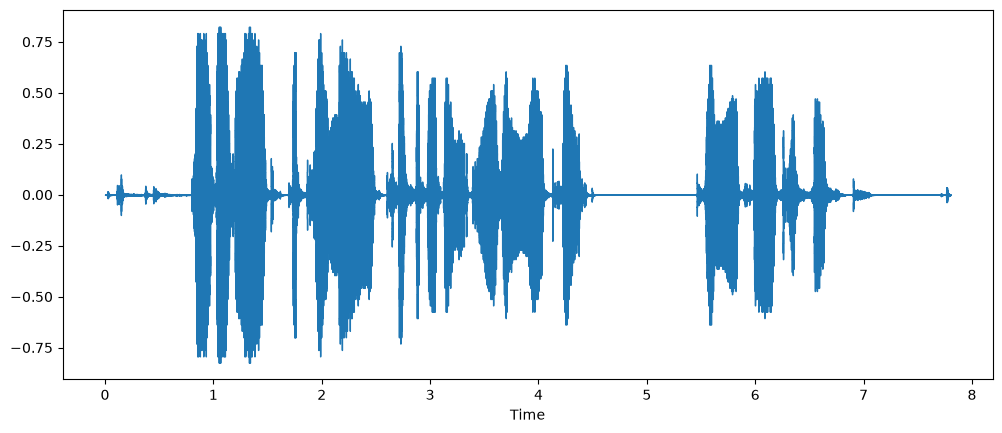

In [9]:
array = example["audio"]["array"]
sampling_rate = example["audio"]["sampling_rate"]

plt.figure().set_figwidth(12)
librosa.display.waveshow(array, sr=sampling_rate)
plt.show()

min = 2.0 s | medie = 8.4 s | max = 57.4 s | peste 20 s: 30


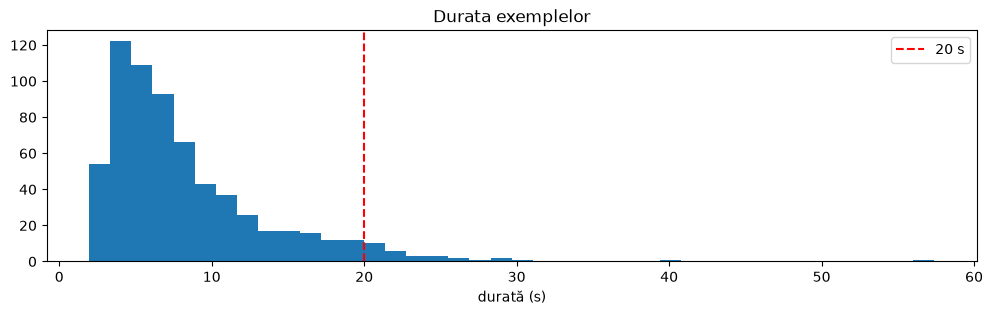

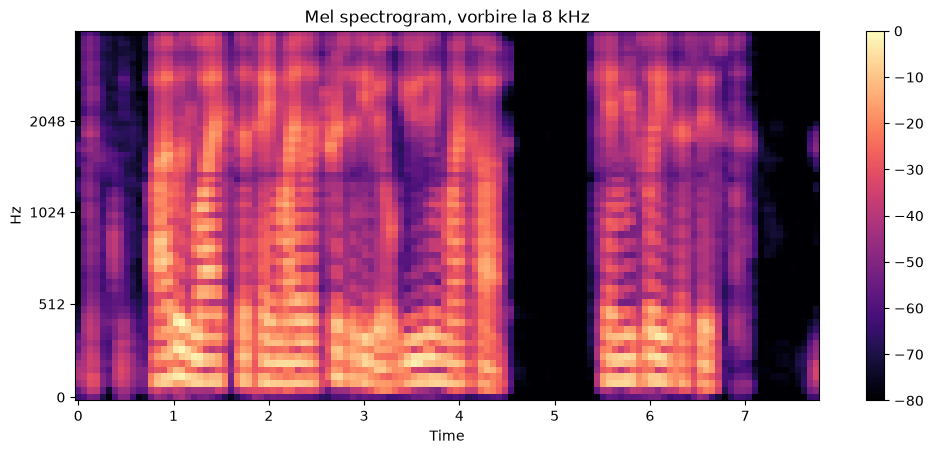

In [10]:
# 🧪 TODO 1: calculează durata fiecărui exemplu și desenează histograma duratelor.
# TODO: câte exemple au peste 20 s? (în modulul următor le vom filtra)
durations = np.array([len(a["array"]) / a["sampling_rate"] for a in minds["audio"]])
print(f"min = {durations.min():.1f} s | medie = {durations.mean():.1f} s | max = {durations.max():.1f} s | peste 20 s: {(durations > 20).sum()}")

plt.figure(figsize=(12, 3))
plt.hist(durations, bins=40); plt.axvline(20, color="red", linestyle="--", label="20 s")
plt.xlabel("durată (s)"); plt.legend(); plt.title("Durata exemplelor")
plt.show()
# Răspuns: 30 de exemple au peste 20 s. După filtrare rămân 624, exact cât arată cursul la Preprocessing.

# 🧪 TODO 2: mel spectrogram pentru exemplul de mai sus. Atenție la fmax: ce frecvență maximă există la 8 kHz?
S = librosa.feature.melspectrogram(y=array, sr=sampling_rate, n_mels=64, fmax=4000)
plt.figure().set_figwidth(12)
librosa.display.specshow(librosa.power_to_db(S, ref=np.max), x_axis="time", y_axis="mel", sr=sampling_rate, fmax=4000)
plt.colorbar(); plt.title("Mel spectrogram, vorbire la 8 kHz")
plt.show()
# Răspuns: la 8 kHz nu există nimic peste 4 kHz (Nyquist), de aceea fmax=4000.
# Compară cu trompeta din ghidul 01: aici vezi silabe și pauze, nu note lungi.

## 6. 🎯 Legătura cu proiectul

📖 Dataset-ul nostru, [`speechbrain/LoquaciousSet`](https://huggingface.co/datasets/speechbrain/LoquaciousSet) (fost `LargeScaleASR`), are aceeași idee, cu câteva diferențe:

| | MINDS-14 | LoquaciousSet |
|---|---|---|
| Mărime | 654 de exemple (en-AU) | ~25.000 de ore |
| Audio | decodat (`array`) | **bytes WAV** în coloana `wav` |
| Sampling rate | 8 kHz | 16 kHz (de confirmat) |
| Text | cu majuscule și punctuație | UPPERCASE, fără punctuație |
| Încărcare | download complet | **streaming** (ghidul 04) |

In [11]:
# 🧪 TODO: încarcă alt subset de limbă (ex. "fr-FR") și compară: câte exemple are, ce sampling rate, cum arată textul?
minds_fr = load_dataset("PolyAI/minds14", name="fr-FR", split="train")
ex_fr = minds_fr[0]
print(minds_fr.num_rows, "exemple |", ex_fr["audio"]["sampling_rate"], "Hz")
print("transcription:        ", ex_fr["transcription"])
print("english_transcription:", ex_fr["english_transcription"])
Audio(ex_fr["audio"]["array"], rate=ex_fr["audio"]["sampling_rate"])
# Observă: pentru fr-FR, english_transcription chiar e o traducere, deci nu mai e duplicat.

539 exemple | 8000 Hz
transcription:         je souhaite changer mon adresse
english_transcription: I want to change my address


## 📌 Ce trebuie să reții
- `load_dataset(id, name=config, split=...)` încarcă un dataset de pe Hub. Prima oară îl descarcă, apoi îl ia din cache.
- Coloana audio dă `array` (float32, 1-D) și `sampling_rate`. În `datasets` 5 e un `AudioDecoder`, care decodează la cerere.
- `ClassLabel` stochează numere. Cu `int2str` sau `.names` treci la text.
- `remove_columns` scoate coloanele inutile.
- **Explorează datele înainte să antrenezi:**
  - ascultă exemple;
  - desenează waveform-ul și spectrograma;
  - uită-te la distribuția duratelor și a etichetelor.
- Primul semnal de alarmă aici: **8 kHz ≠ 16 kHz**, deci trebuie resampling.

## ❓ Verifică-te
<details><summary><b>1. Ce face parametrul `name` din `load_dataset`?</b></summary>

Alege **configurația** (subsetul) dataset-ului. La MINDS-14, configurația e limba: `en-AU`, `fr-FR` etc.

</details>

<details><summary><b>2. De ce nu putem da direct audio-ul din MINDS-14 lui Whisper?</b></summary>

E la **8 kHz**, iar Whisper e antrenat la **16 kHz**. Trebuie resampling (modulul următor).

</details>

<details><summary><b>3. Cum transformi `intent_class = 13` în text?</b></summary>

`minds.features["intent_class"].int2str(13)` → `"pay_bill"`.

</details>

<details><summary><b>4. De ce ne interesează distribuția duratelor?</b></summary>

Exemplele foarte lungi consumă multă memorie și pot fi tăiate de model (Whisper taie la 30 s), deci le filtrăm. Durata contează și pentru numărul de tokeni audio din proiect.

</details>

<details><summary><b>5. Ce e diferit la dataset-ul proiectului față de MINDS-14?</b></summary>

E uriaș, deci îl folosim în **streaming**. Audio-ul vine ca **bytes WAV**, pe care trebuie să-i decodăm noi. Textul e UPPERCASE, fără punctuație.

</details>

## ➡️ Următorul: `03_preprocessing.ipynb` (urmează)